# Dense → Mixture-of-Experts: train a dense LM, convert it, keep training

1. Train a 20.8M-parameter dense decoder-only LM on 30M tokens of TinyStories.
2. Convert its feed-forward blocks into 8 experts per layer in three ways (copy, drop-upcycling, partition) and give each layer a fresh top-2 router.
3. Keep training every converted model and a dense control on the **same next 20M tokens**, and check that the loss keeps going down.

Training runs skip themselves when their `results/<name>.json` and checkpoint already exist, so on a fresh Colab
this notebook trains everything (~75 min on a T4-class GPU is a rough guess; the committed outputs come from an RTX 4060 Laptop GPU),
and locally it just loads the finished runs. The full plain-text training logs are in `logs/`.

In [1]:
# Colab: clones the repo and installs the two extra packages. Locally (inside the repo) it does nothing.
import os
if not os.path.exists('moe'):
    !git clone -q https://github.com/shekar-maker/-dense-to-moe-upcycling.git
    %cd ./-dense-to-moe-upcycling
    !pip -q install datasets tokenizers
import json, torch, numpy as np
from IPython.display import Markdown, Image, display
from moe.model import LM, Config
from moe.upcycle import upcycle, expert_similarity
from moe.train import setup_cuda, evaluate, load_model, sample
from moe.data import prepare, TokenLoader
from moe import experiments as X, report as R
print(setup_cuda())

{'gpu': 'NVIDIA GeForce RTX 4060 Laptop GPU', 'total_gib': 7.99560546875, 'torch': '2.11.0+cu128'}


In [2]:
def table(rows, cols, fmt=None):
    fmt = fmt or {}
    out = '| ' + ' | '.join(cols) + ' |\n|' + '---|' * len(cols) + '\n'
    for r in rows:
        out += '| ' + ' | '.join(fmt.get(c, '{}').format(r[c]) if c in r else '' for c in cols) + ' |\n'
    display(Markdown(out))

## 1. Data

TinyStories, an 8,192-token byte-level BPE, 52M train tokens and 1M validation tokens (only the first ~234k stories are streamed).

In [3]:
meta = prepare('data')
print(meta)

{'vocab_size': 8192, 'eos_id': 0, 'train_tokens': 52000000, 'train_stories': 234249, 'val_tokens': 1000000, 'val_stories': 5081}


## 2. Train the dense model (30M tokens)

In [4]:
log_dense, dense = X.run_dense()
print(f"val loss {log_dense['val_loss'][0]:.4f} -> {log_dense['final_val_loss']:.4f} in {log_dense['wall_s']/60:.1f} min")
print(open('logs/dense.log').read()[-1500:])

[dense] loaded finished run: final val 1.7546


val loss 9.0757 -> 1.7546 in 8.0 min
oss 1.7681
step  1710/1831 | tokens  28.02M | loss 1.8355 | lr 1.10e-04 | gnorm 0.43 |  71,356 tok/s
step  1720/1831 | tokens  28.18M | loss 1.8616 | lr 1.09e-04 | gnorm 0.44 |  65,939 tok/s
step  1730/1831 | tokens  28.34M | loss 1.7545 | lr 1.07e-04 | gnorm 0.42 |  65,878 tok/s
step  1740/1831 | tokens  28.51M | loss 1.8802 | lr 1.06e-04 | gnorm 0.43 |  65,744 tok/s
step  1750/1831 | tokens  28.67M | loss 1.8798 | lr 1.05e-04 | gnorm 0.44 |  65,864 tok/s
step  1760/1831 | tokens  28.84M | loss 1.7524 | lr 1.04e-04 | gnorm 0.43 |  65,903 tok/s
eval step  1769 | tokens  28.98M | val loss 1.7617
step  1770/1831 | tokens  29.00M | loss 1.8387 | lr 1.03e-04 | gnorm 0.43 |  71,168 tok/s
step  1780/1831 | tokens  29.16M | loss 1.8428 | lr 1.02e-04 | gnorm 0.43 |  65,909 tok/s
step  1790/1831 | tokens  29.33M | loss 1.8900 | lr 1.01e-04 | gnorm 0.44 |  65,875 tok/s
step  1800/1831 | tokens  29.49M | loss 1.8154 | lr 1.01e-04 | gnorm 0.45 |  65,905 tok/s
s

## 3. The conversion

Attention, embeddings and norms are copied. Each layer's SwiGLU MLP (384 → 2×1,024 → 384) becomes 8 experts:

* **copy**: every expert is the dense MLP. The top-2 weights add up to one, so the MoE model computes exactly the dense function.
* **drop** (r = 0.5): every expert is a copy with a random half of its 1,024 inner neurons redrawn from the original matrices' mean and std.
* **partition**: every expert takes a random 512 of the 1,024 neurons (the subsets overlap), and the output is scaled by 1,024 / 512 = 2. Two experts of 512 are the same compute per token as the dense MLP.

The router is new in every case (std 0.002, softmax over 8, top-2, renormalised). Below is the validation loss **at the moment of conversion, before any training**.

In [5]:
val = TokenLoader('data/val.bin', 16, 512, 'cuda').fixed_batches(16, 16)
rows = [{'model': 'dense', 'params': dense.n_params(), 'active': dense.n_active_params(), 'val': evaluate(dense, val)}]
for name, spec in X.MOE_RUNS.items():
    spec = {k: v for k, v in spec.items() if k != 'accum'}
    m = upcycle(dense, spec.pop('method'), **spec)
    rows.append({'model': name, 'params': m.n_params(), 'active': m.n_active_params(), 'val': evaluate(m, val),
                 'cos': float(np.mean(expert_similarity(m)))})
    del m; torch.cuda.empty_cache()
for r in rows:
    r['delta'] = r['val'] - rows[0]['val']
json.dump(rows, open('results/conversion.json', 'w'), indent=1)
table(rows, ['model', 'params', 'active', 'val', 'delta', 'cos'],
      {'params': '{:,}', 'active': '{:,}', 'val': '{:.4f}', 'delta': '{:+.4f}', 'cos': '{:.3f}'})

| model | params | active | val | delta | cos |
|---|---|---|---|---|---|
| dense | 20,848,512 | 20,848,512 | 1.7546 | +0.0000 |  |
| moe_copy | 103,454,592 | 32,675,712 | 1.7546 | -0.0000 | 0.999 |
| moe_drop | 103,454,592 | 32,675,712 | 2.2503 | +0.4956 | 0.250 |
| moe_partition | 56,268,672 | 20,879,232 | 1.9368 | +0.1822 | 0.036 |
| moe_copy_nobal | 103,454,592 | 32,675,712 | 1.7546 | -0.0000 | 0.999 |


## 4. Keep training: the dense control and four MoE runs (20M tokens each)

In [6]:
del dense; torch.cuda.empty_cache()
logs = X.run_all(['dense_continue', *X.MOE_RUNS])
for n in logs:
    print(f'--- logs/{n}.log (first and last lines)')
    lines = open(f'logs/{n}.log').read().splitlines()
    print('\n'.join(lines[:5] + ['...'] + lines[-4:]))

[dense_continue] loaded finished run: final val 1.6624


[moe_copy] loaded finished run: final val 1.6449


[moe_drop] loaded finished run: final val 1.6606


[moe_partition] loaded finished run: final val 1.6764


[moe_copy_nobal] loaded finished run: final val 1.6572


--- logs/dense_continue.log (first and last lines)
run dense_continue: dense, 20,848,512 parameters (20,848,512 active per token), 1220 steps x 16,384 tokens, lr 0.0003 (warm-up 36, cosine to 0.1x)
eval step     0 | tokens   0.00M | val loss 1.7546
step    10/1220 | tokens   0.16M | loss 1.8352 | lr 8.33e-05 | gnorm 0.43 |  64,779 tok/s
step    20/1220 | tokens   0.33M | loss 1.7431 | lr 1.67e-04 | gnorm 0.44 |  65,895 tok/s
step    30/1220 | tokens   0.49M | loss 1.7916 | lr 2.50e-04 | gnorm 0.44 |  65,881 tok/s
...
step  1210/1220 | tokens  19.82M | loss 1.7545 | lr 3.01e-05 | gnorm 0.47 |  65,790 tok/s
step  1220/1220 | tokens  19.99M | loss 1.7091 | lr 3.00e-05 | gnorm 0.45 |  65,867 tok/s
eval step  1220 | tokens  19.99M | val loss 1.6624
done dense_continue: val loss 1.7546 -> 1.6624, 66,523 tok/s, peak 4.98 GiB, 5.3 min
--- logs/moe_copy.log (first and last lines)
run moe_copy: moe, 103,454,592 parameters (32,675,712 active per token), 1220 steps x 16,384 tokens, lr 0.0003 (warm

## 5. Results

In [7]:
CONT = ['dense_continue', *X.MOE_RUNS]
rows = R.summary(['dense', *CONT])
json.dump(rows, open('results/summary.json', 'w'), indent=1)
table(rows, ['run', 'params', 'active', 'tokens', 'val_start', 'val_end', 'train_end', 'tok_s', 'minutes', 'peak_gib',
             'maxvio_end', 'starved_end', 'dead_end', 'cos_start', 'cos_end'],
      {'params': '{:,}', 'active': '{:,}', 'tokens': '{:,}', 'val_start': '{:.4f}', 'val_end': '{:.4f}', 'train_end': '{:.4f}',
       'tok_s': '{:,.0f}', 'minutes': '{:.1f}', 'peak_gib': '{:.2f}', 'maxvio_end': '{:.2f}', 'starved_end': '{:.1f}',
       'dead_end': '{:.1f}', 'cos_start': '{:.3f}', 'cos_end': '{:.3f}'})

| run | params | active | tokens | val_start | val_end | train_end | tok_s | minutes | peak_gib | maxvio_end | starved_end | dead_end | cos_start | cos_end |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| dense | 20,848,512 | 20,848,512 | 29,999,104 | 9.0757 | 1.7546 | 1.8270 | 65,930 | 7.6 | 4.98 |  |  |  |  |  |
| dense_continue | 20,848,512 | 20,848,512 | 19,988,480 | 1.7546 | 1.6624 | 1.7103 | 65,794 | 5.1 | 4.98 |  |  |  |  |  |
| moe_copy | 103,454,592 | 32,675,712 | 19,988,480 | 1.7546 | 1.6449 | 1.6952 | 31,438 | 10.6 | 5.43 | 0.04 | 0.0 | 0.0 | 0.999 | 0.965 |
| moe_drop | 103,454,592 | 32,675,712 | 19,988,480 | 2.2503 | 1.6606 | 1.7109 | 22,247 | 15.0 | 5.43 | 0.03 | 0.0 | 0.0 | 0.250 | 0.252 |
| moe_partition | 56,268,672 | 20,879,232 | 19,988,480 | 1.9368 | 1.6764 | 1.7285 | 36,695 | 9.1 | 6.79 | 0.03 | 0.0 | 0.0 | 0.036 | 0.035 |
| moe_copy_nobal | 103,454,592 | 32,675,712 | 19,988,480 | 1.7546 | 1.6572 | 1.7056 | 22,151 | 15.0 | 5.44 | 2.89 | 52.0 | 0.0 | 0.999 | 0.964 |


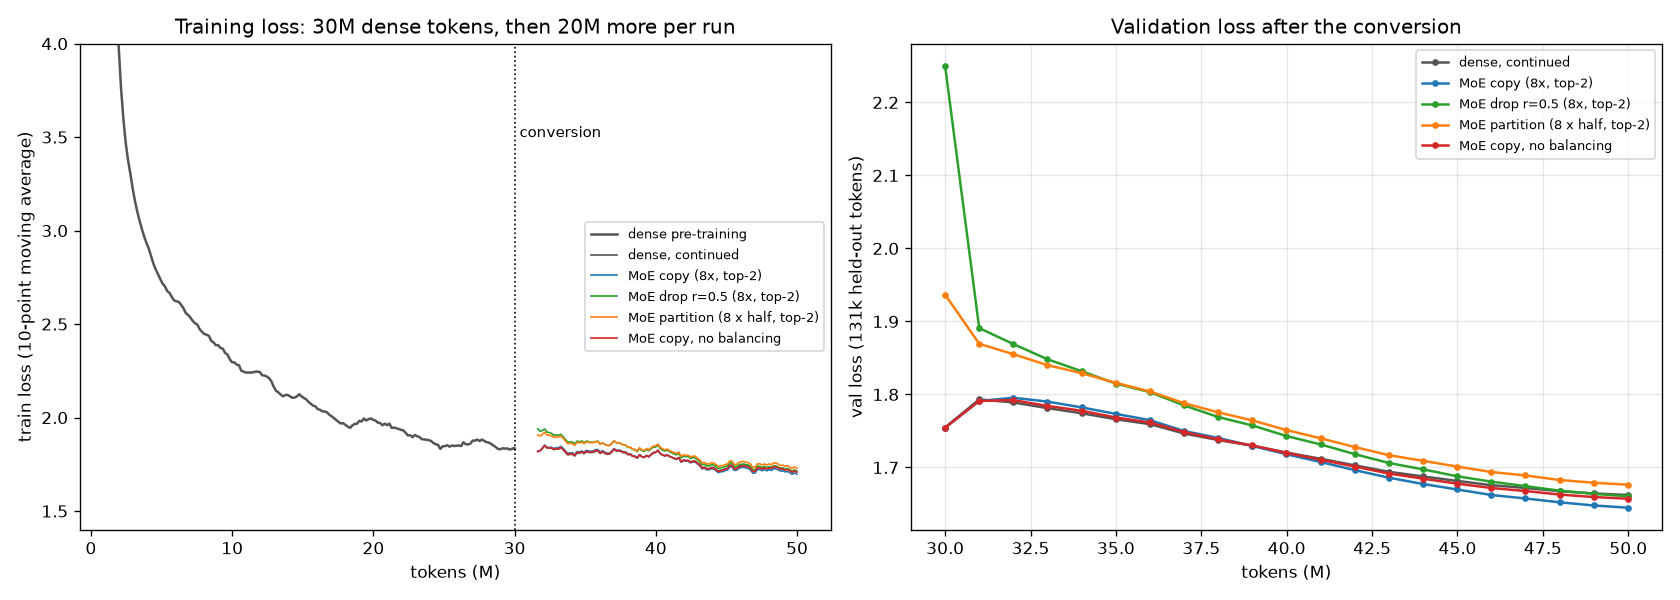

In [8]:
display(Image(R.plot_curves(CONT)))

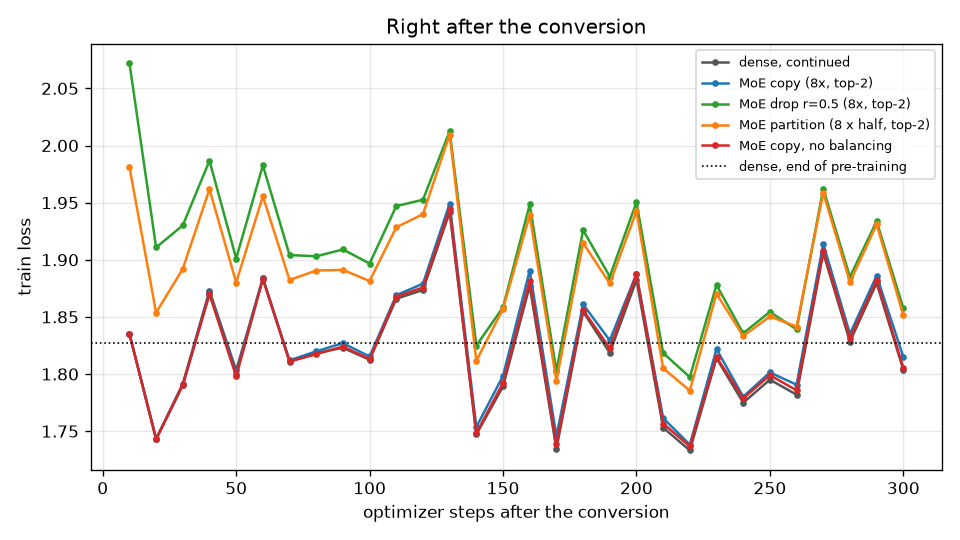

In [9]:
display(Image(R.plot_conversion_zoom(CONT)))

## 6. Routing: load balance and how fast the copies become different

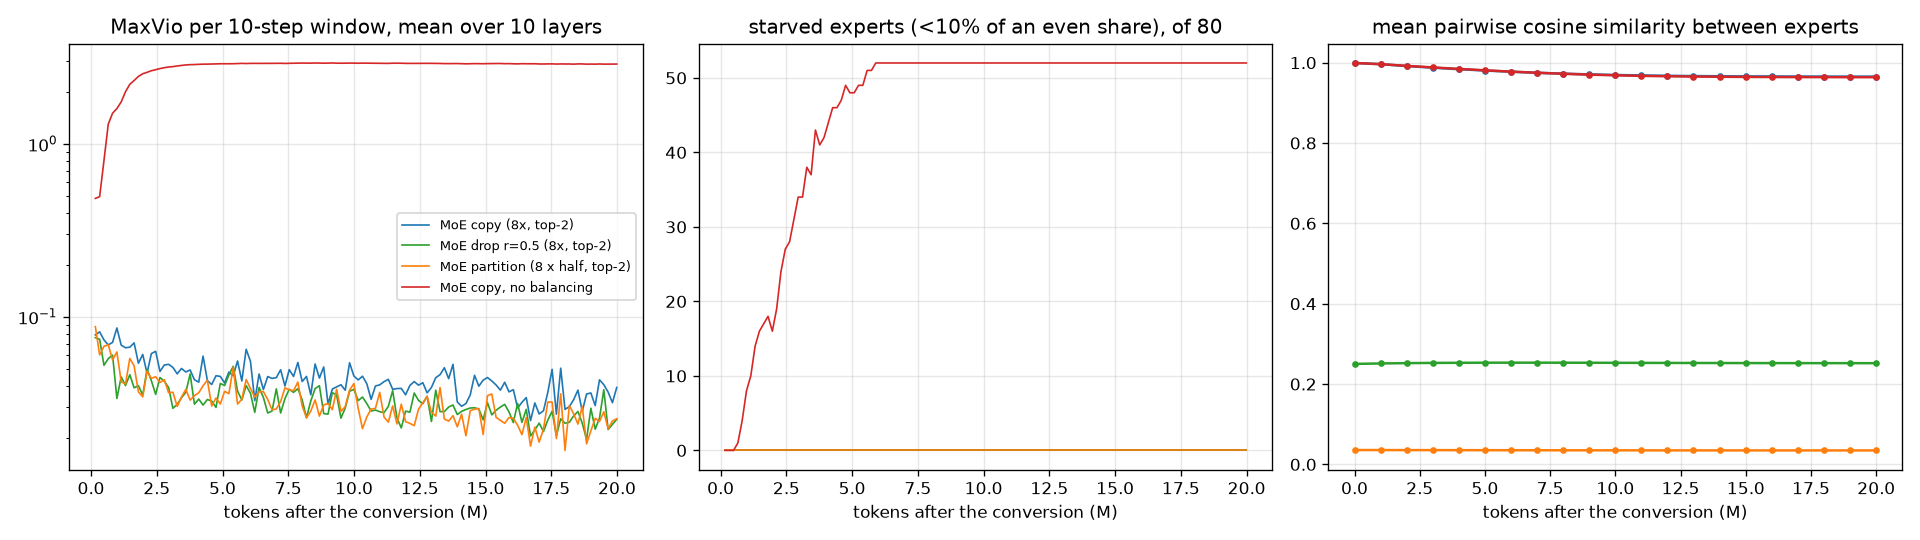

In [10]:
display(Image(R.plot_routing(list(X.MOE_RUNS))))

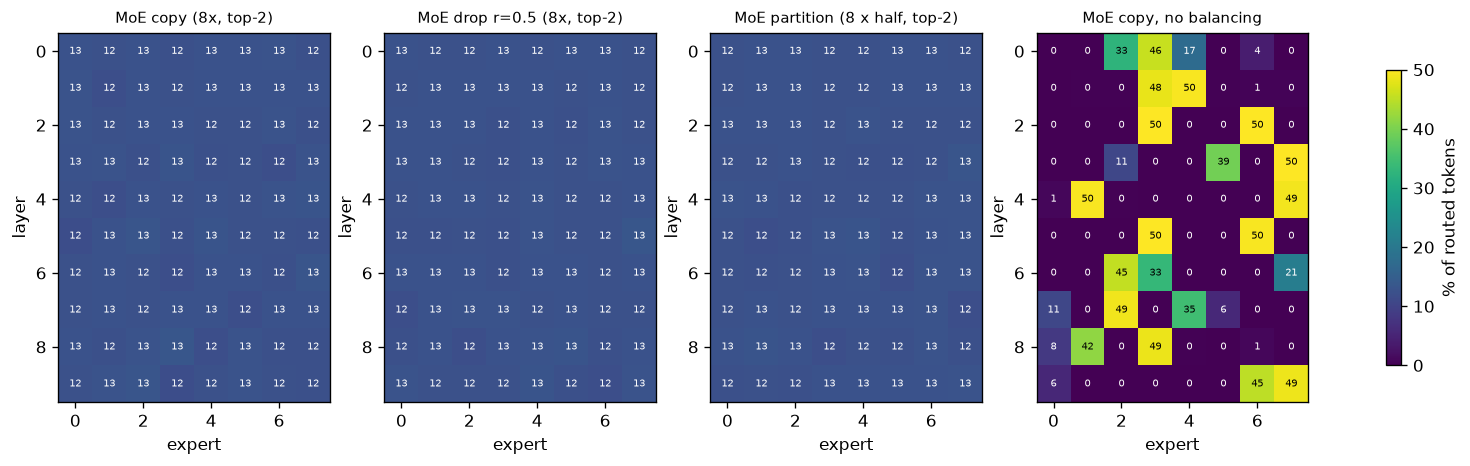

In [11]:
display(Image(R.plot_load_heatmaps(list(X.MOE_RUNS))))

## 7. Samples (same prompts, same seed)

In [12]:
prompts = ['Once upon a time, there was a little dog named', 'Tom and Mia went to the park. They saw']
samples = {}
for n in ['dense_continue', 'moe_copy', 'moe_partition']:
    m = load_model(f'checkpoints/{n}.pt')
    samples[n] = sample(m, prompts)
    del m; torch.cuda.empty_cache()
    print(f'=== {n}')
    for s in samples[n]:
        print(s, '\n')
json.dump(samples, open('results/samples.json', 'w'), indent=1)

=== dense_continue
Once upon a time, there was a little dog named Max. Max liked to play with his toys in the park. One day, Max found a red ball and he wanted to play with it. He held the ball in his hand and he kicked it until he could run around the playground.

But suddenly, something strange happened. The ball broke and Max fell down. He didn't get up and he felt very sad. His friend, a little girl named Lily, saw what happened and asked what happened. Lily explained that her red ball broke in two. Max had an idea. "I know! Let's try again tomorrow!" he said 

Tom and Mia went to the park. They saw a big boy with a hat and a hat. He looked sad. Tom and Mia wanted to help.

"Can we help you? Can we be your friends?" Tom asked.

"Yes, we can. He will be my friends," Mia said.

"OK. But be careful. Don't make a sound or move or talk," Tom said. He was not sure.

They went to the swings and swung on the swings. They had fun. The sun was hot. The sun was shining. Tom and Mia were happy

=== moe_copy
Once upon a time, there was a little dog named Max. Max liked to play with his toys in the park. One day, Max found a red ball and started to play with it. He bounced it over to see his owner, Lily.

"Can I play with your ball, please?" asked Max.

"No, I want to play," said Lily. "That ball looks funny."

Max was sad, but he understood. He ran to Lily's house and found her ball under the swings. He picked up the ball and threw it back to Lily. Lily was happy that Max forgave her and they played together 

Tom and Mia went to the park. They saw a big hole in the fence. The hole was dark and scary. They could not see anything.

"Let's go back," Tom said. "The box is dark and scary."

"No, Tom," Mia said. "We can't go there. The box is too old and dangerous. We should stay here."

They started to cry. They did not want to go near the box.

Then they saw something shiny in the grass. It was a necklace with a big star. It was shiny and sparkly.

"Wow, look at this 



=== moe_partition
Once upon a time, there was a little dog named Max. Max liked to play with his toys in the park. One day, Max found a red ball and started to play with it. He rolled it over to see his owner, Lily.

"Can I play with your ball, please?" asked Max.

"No, I want to play with my ball," replied Lily.

Max felt sad and walked away. But then, he remembered that he had a new toy car. He went back to them and picked up the red ball. "This toy is so pretty!" he said.

Lily and Max played 

Tom and Mia went to the park. They saw a big boy with a hat and a hat. He looked sad. Tom and Mia wanted to help.

"Hi, can we be your friend?" Tom asked.

The big boy looked at Tom and Mia. He was not afraid. He walked over and said softly, "Hi, I'm Ben and this is my mom. She is sick. Can I play with your ball for a little while?"

Tom and Mia smiled. They wanted to play with the ball. They walked to the ball and reached for it. But the ball was too far away. They could 

